In [3]:
import os

PATH_1 = '/kaggle/input/datasets/ittisamurtunib/path-3seed-ssl-finetune'
PATH_2 = '/kaggle/input/datasets/ittisamurtunib/ssl-finetune-adaptive-weights-pth'

files_path_1 = [
    'test_probs_seed42.csv',
    'test_probs_seed123.csv',
    'test_probs_seed2024.csv',
    'ssl_rebalance_3seed_results.json'
]

file_path_2 = 'ssl_adaptive_weight_3seed_results.json'

# Verify files in dataset 1
for f in files_path_1:
    full_path = os.path.join(PATH_1, f)
    print(f"{f} exists: {os.path.exists(full_path)}")

# Verify file in dataset 2
full_path_2 = os.path.join(PATH_2, file_path_2)
print(f"{file_path_2} exists: {os.path.exists(full_path_2)}")

test_probs_seed42.csv exists: True
test_probs_seed123.csv exists: True
test_probs_seed2024.csv exists: True
ssl_rebalance_3seed_results.json exists: True
ssl_adaptive_weight_3seed_results.json exists: True


fixed   seed 42: MEL AP = 0.2216
fixed   seed 123: MEL AP = 0.1904
fixed   seed 2024: MEL AP = 0.2135

Fixed-weight MEL AP: 0.2085 +/- 0.0132

Operating points:
  seed 42: fixed=(R0.38, P0.20)  adaptive=(R0.50, P0.20)
  seed 123: fixed=(R0.50, P0.19)  adaptive=(R0.50, P0.17)
  seed 2024: fixed=(R0.38, P0.21)  adaptive=(R0.38, P0.14)


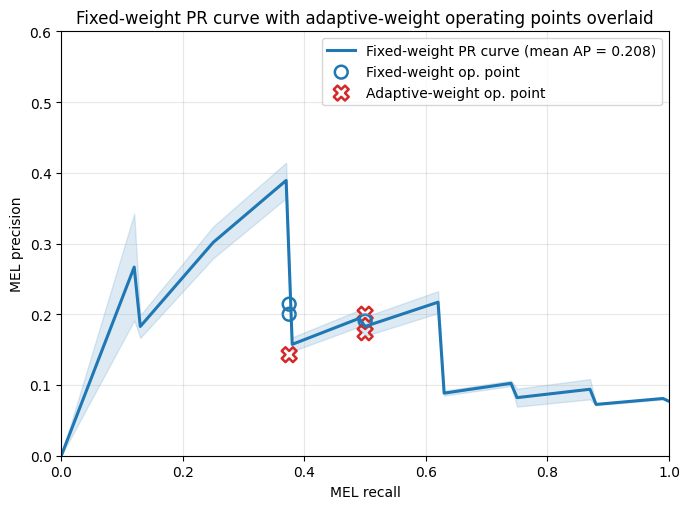


Saved summary -> /kaggle/working/Thesis_Outputs/pr_analysis.json
Saved figure  -> /kaggle/working/Thesis_Outputs/pr_curve_with_adaptive_ops.png


In [5]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, precision_recall_curve

# Input Dataset Paths
PATH_1 = '/kaggle/input/datasets/ittisamurtunib/path-3seed-ssl-finetune'
PATH_2 = '/kaggle/input/datasets/ittisamurtunib/ssl-finetune-adaptive-weights-pth'

# Output directory for saved plots and summary json
OUT = '/kaggle/working/Thesis_Outputs'
os.makedirs(OUT, exist_ok=True)

CLASSES = ['BKL', 'MEL', 'NV']
SEEDS = [42, 123, 2024]

# ---------- 1. Fixed-weight AP and PR curve from the three CSVs ----------
fixed = {}
for s in SEEDS:
    df = pd.read_csv(f'{PATH_1}/test_probs_seed{s}.csv')
    y_mel = (df['true_label'].values == 'MEL').astype(int)
    p_mel = df['MEL'].values
    ap = average_precision_score(y_mel, p_mel)
    prec, rec, _ = precision_recall_curve(y_mel, p_mel)
    fixed[s] = {'ap': ap, 'prec': prec, 'rec': rec}
    print(f"fixed   seed {s}: MEL AP = {ap:.4f}")

fixed_ap_mean = np.mean([fixed[s]['ap'] for s in SEEDS])
fixed_ap_std  = np.std([fixed[s]['ap'] for s in SEEDS])
print(f"\nFixed-weight MEL AP: {fixed_ap_mean:.4f} +/- {fixed_ap_std:.4f}")

# ---------- 2. Operating points from the two JSONs ----------
with open(f'{PATH_1}/ssl_rebalance_3seed_results.json') as f:
    fixed_json = json.load(f)
with open(f'{PATH_2}/ssl_adaptive_weight_3seed_results.json') as f:
    adaptive_json = json.load(f)

fixed_ops = {s: fixed_json[str(s)]['report']['MEL'] for s in SEEDS}
adapt_ops = {s: adaptive_json[str(s)]['report']['MEL'] for s in SEEDS}

print("\nOperating points:")
for s in SEEDS:
    print(f"  seed {s}: fixed=(R{fixed_ops[s]['recall']:.2f}, P{fixed_ops[s]['precision']:.2f})  "
          f"adaptive=(R{adapt_ops[s]['recall']:.2f}, P{adapt_ops[s]['precision']:.2f})")

# ---------- 3. Plot ----------
common_recall = np.linspace(0, 1, 101)
interps = [np.interp(common_recall, fixed[s]['rec'][::-1], fixed[s]['prec'][::-1])
           for s in SEEDS]
interps = np.stack(interps)
mean_p, std_p = interps.mean(0), interps.std(0)

fig, ax = plt.subplots(figsize=(7, 5.2))
ax.plot(common_recall, mean_p, color='tab:blue', lw=2.2,
        label=f'Fixed-weight PR curve (mean AP = {fixed_ap_mean:.3f})')
ax.fill_between(common_recall,
                np.clip(mean_p - std_p, 0, 1),
                np.clip(mean_p + std_p, 0, 1),
                color='tab:blue', alpha=0.15)

for i, s in enumerate(SEEDS):
    ax.scatter(fixed_ops[s]['recall'], fixed_ops[s]['precision'],
               marker='o', s=85, facecolors='none', edgecolors='tab:blue',
               linewidths=1.8,
               label='Fixed-weight op. point' if i == 0 else None)
    ax.scatter(adapt_ops[s]['recall'], adapt_ops[s]['precision'],
               marker='X', s=115, facecolors='none', edgecolors='tab:red',
               linewidths=1.8,
               label='Adaptive-weight op. point' if i == 0 else None)

ax.set_xlabel('MEL recall')
ax.set_ylabel('MEL precision')
ax.set_title('Fixed-weight PR curve with adaptive-weight operating points overlaid')
ax.set_xlim(0, 1)
ax.set_ylim(0, max(0.6, mean_p.max() + 0.05))
ax.legend(loc='upper right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{OUT}/pr_curve_with_adaptive_ops.png', dpi=160, bbox_inches='tight')
plt.show()

# ---------- 4. Save summary for the paper ----------
summary = {
    'fixed_ap_mean': float(fixed_ap_mean),
    'fixed_ap_std':  float(fixed_ap_std),
    'fixed_ap_per_seed':  {str(s): float(fixed[s]['ap']) for s in SEEDS},
    'fixed_ops':  {str(s): {'recall': float(fixed_ops[s]['recall']),
                            'precision': float(fixed_ops[s]['precision'])} for s in SEEDS},
    'adapt_ops':  {str(s): {'recall': float(adapt_ops[s]['recall']),
                            'precision': float(adapt_ops[s]['precision'])} for s in SEEDS},
}
with open(f'{OUT}/pr_analysis.json', 'w') as f:
    json.dump(summary, f, indent=2)

print(f"\nSaved summary -> {OUT}/pr_analysis.json")
print(f"Saved figure  -> {OUT}/pr_curve_with_adaptive_ops.png")